In [1]:
import pandas as pd
df=pd.read_csv('employee_data.csv')
df.head(10)

,EmpID,FirstName,LastName,StartDate,ExitDate,Title,Supervisor,ADEmail,BusinessUnit,EmployeeStatus,...,Division,DOB,State,JobFunctionDescription,GenderCode,LocationCode,RaceDesc,MaritalDesc,Performance Score,Current Employee Rating
0,3427,Uriah,Bridges,20-Sep-19,NaN,Production Technician I,Peter Oneill,uriah.bridges@bilearner.com,CCDR,Active,...,Finance & Accounting,07-10-1969,MA,Accounting,Female,34904,White,Widowed,Fully Meets,4
1,3428,Paula,Small,11-Feb-23,NaN,Production Technician I,Renee Mccormick,paula.small@bilearner.com,EW,Active,...,Aerial,30-08-1965,MA,Labor,Male,6593,Hispanic,Widowed,Fully Meets,3
2,3429,Edward,Buck,10-Dec-18,NaN,Area Sales Manager,Crystal Walker,edward.buck@bilearner.com,PL,Active,...,General - Sga,06-10-1991,MA,Assistant,Male,2330,Hispanic,Widowed,Fully Meets,4
3,3430,Michael,Riordan,21-Jun-21,NaN,Area Sales Manager,Rebekah Wright,michael.riordan@bilearner.com,CCDR,Active,...,Finance & Accounting,04-04-1998,ND,Clerk,Male,58782,Other,Single,Fully Meets,2
4,3431,Jasmine,Onque,29-Jun-19,NaN,Area Sales Manager,Jason Kim,jasmine.onque@bilearner.com,TNS,Active,...,General - Con,29-08-1969,FL,Laborer,Female,33174,Other,Married,Fully Meets,3
5,3432,Maruk,Fraval,17-Jan-20,NaN,Area Sales Manager,Sheri Campos,maruk.fraval@bilearner.com,BPC,Active,...,Field Operations,03-04-1949,CT,Driver,Male,6050,Black,Married,Fully Meets,3
6,3433,Latia,Costa,06-Apr-22,03-Jul-23,Area Sales Manager,Jacob Braun,latia.costa@bilearner.com,WBL,Active,...,General - Eng,01-07-1942,CA,Technician,Female,90007,Hispanic,Divorced,Exceeds,4
7,3434,Sharlene,Terry,06-Nov-20,29-Jan-23,Area Sales Manager,Tracy Marquez,sharlene.terry@bilearner.com,CCDR,Active,...,Engineers,07-03-1957,OR,Engineer,Female,97756,White,Divorced,Fully Meets,2
8,3435,Jac,McKinzie,18-Aug-18,NaN,Area Sales Manager,Sharon Becker,jac.mckinzie@bilearner.com,NEL,Active,...,Executive,15-05-1974,TX,Executive Assistant,Male,78789,Black,Widowed,Exceeds,3
9,3436,Joseph,Martins,21-Jan-22,29-Jun-23,Area Sales Manager,George Jenkins,joseph.martins@bilearner.com,BPC,Active,...,Engineers,11-11-1949,TX,Engineer,Male,78207,Asian,Widowed,Fully Meets,5


In [2]:
df.shape

(3000, 26)

In [3]:
df.isnull().sum()
#exit date and termination type have missing values because not all employees left

EmpID                            0
FirstName                        0
LastName                         0
StartDate                        0
ExitDate                      1467
Title                            0
Supervisor                       0
ADEmail                          0
BusinessUnit                     0
EmployeeStatus                   0
EmployeeType                     0
PayZone                          0
EmployeeClassificationType       0
TerminationType                  0
TerminationDescription        1467
DepartmentType                   0
Division                         0
DOB                              0
State                            0
JobFunctionDescription           0
GenderCode                       0
LocationCode                     0
RaceDesc                         0
MaritalDesc                      0
Performance Score                0
Current Employee Rating          0
dtype: int64

In [4]:
df.dtypes

EmpID                         int64
FirstName                       str
LastName                        str
StartDate                       str
ExitDate                        str
Title                           str
Supervisor                      str
ADEmail                         str
BusinessUnit                    str
EmployeeStatus                  str
EmployeeType                    str
PayZone                         str
EmployeeClassificationType      str
TerminationType                 str
TerminationDescription          str
DepartmentType                  str
Division                        str
DOB                             str
State                           str
JobFunctionDescription          str
GenderCode                      str
LocationCode                  int64
RaceDesc                        str
MaritalDesc                     str
Performance Score               str
Current Employee Rating       int64
dtype: object

In [5]:
df['Performance Score'].unique()

<StringArray>
['Fully Meets', 'Exceeds', 'Needs Improvement', 'PIP']
Length: 4, dtype: str

In [8]:
df.columns


Index(['EmpID', 'FirstName', 'LastName', 'StartDate', 'ExitDate', 'Title',
       'Supervisor', 'ADEmail', 'BusinessUnit', 'EmployeeStatus',
       'EmployeeType', 'PayZone', 'EmployeeClassificationType',
       'TerminationType', 'TerminationDescription', 'DepartmentType',
       'Division', 'DOB', 'State', 'JobFunctionDescription', 'GenderCode',
       'LocationCode', 'RaceDesc', 'MaritalDesc', 'Performance Score',
       'Current Employee Rating'],
      dtype='str')

In [17]:
print(df['EmployeeStatus'].value_counts())
print(df['DepartmentType'].value_counts())

EmployeeStatus
Active                    2458
Voluntarily Terminated     321
Leave of Absence            86
Future Start                69
Terminated for Cause        66
Name: count, dtype: int64
DepartmentType
Production              2020
IT/IS                    430
Sales                    331
Software Engineering     115
Admin Offices             80
Executive Office          24
Name: count, dtype: int64


In [ ]:
terminated = df[df['EmployeeStatus'].isin(['Voluntary Termination', 'Terminated for Cause'])]
terminated['DepartmentType'].value_counts()


DepartmentType
Production           35
IT/IS                31
Name: count, dtype: int64

In [13]:
pd.crosstab(terminated['DepartmentType'], terminated['EmployeeStatus'], margins=True)

EmployeeStatus,Terminated for Cause,All
DepartmentType,,
IT/IS,31,31
Production,35,35
All,66,66


In [ ]:
df['is_terminated'] = df['EmployeeStatus'].isin(['Voluntarily Terminated', 'Terminated for Cause'])
df.groupby('DepartmentType')['is_terminated'].agg(['sum', 'count', 'mean']).sort_values('mean', ascending=False)


,sum,count,mean
DepartmentType,,,
Software Engineering,20,115,0.173913
Production,322,2020,0.159406
IT/IS,34,430,0.079070
Sales,10,331,0.030211
Admin Offices,1,80,0.012500
Executive Office,0,24,0.000000


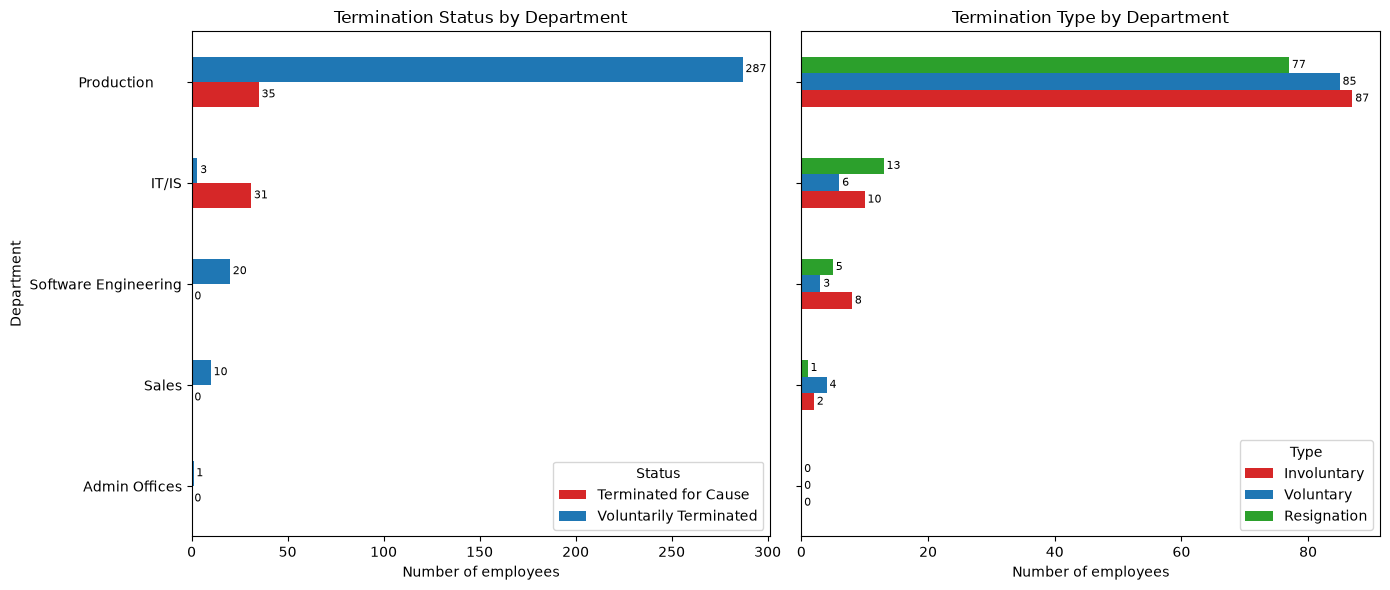

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Only employees who actually left
terminated = df[df['EmployeeStatus'].isin(['Voluntarily Terminated', 'Terminated for Cause'])]

# Termination status by department
status_counts = pd.crosstab(terminated['DepartmentType'], terminated['EmployeeStatus'])

# Termination type by department (only the 3 types of interest)
types = ['Involuntary', 'Voluntary', 'Resignation']
type_counts = (
    pd.crosstab(terminated['DepartmentType'], terminated['TerminationType'])
      .reindex(columns=types, fill_value=0)
)

# Same department order in both panels, largest at top
order = status_counts.sum(axis=1).sort_values().index
status_counts = status_counts.loc[order]
type_counts = type_counts.reindex(order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

status_counts.plot.barh(ax=axes[0], color=['#d62728', '#1f77b4'])
axes[0].set_title('Termination Status by Department')
axes[0].set_xlabel('Number of employees')
axes[0].set_ylabel('Department')
axes[0].legend(title='Status')

type_counts.plot.barh(ax=axes[1], color=['#d62728', '#1f77b4', '#2ca02c'])
axes[1].set_title('Termination Type by Department')
axes[1].set_xlabel('Number of employees')
axes[1].legend(title='Type')

# Count labels on each bar
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, padding=2, fontsize=8)

plt.tight_layout()
plt.savefig('terminations_by_department.png', dpi=200, bbox_inches='tight')
plt.show()

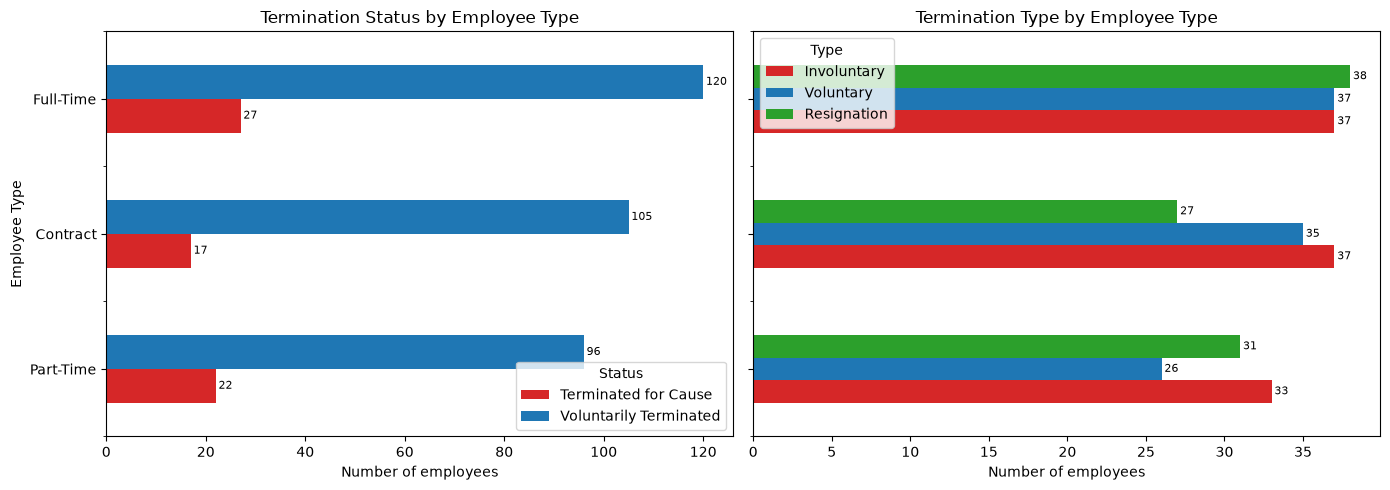

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

terminated = df[df['EmployeeStatus'].isin(['Voluntarily Terminated', 'Terminated for Cause'])]

def plot_terminations(data, group_col, label):
    status_counts = pd.crosstab(data[group_col], data['EmployeeStatus'])
    types = ['Involuntary', 'Voluntary', 'Resignation']
    type_counts = (
        pd.crosstab(data[group_col], data['TerminationType'])
          .reindex(columns=types, fill_value=0)
    )

    order = status_counts.sum(axis=1).sort_values().index
    status_counts = status_counts.loc[order]
    type_counts = type_counts.reindex(order, fill_value=0)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

    status_counts.plot.barh(ax=axes[0], color=['#d62728', '#1f77b4'])
    axes[0].set_title(f'Termination Status by {label}')
    axes[0].set_xlabel('Number of employees')
    axes[0].set_ylabel(label)
    axes[0].legend(title='Status')

    type_counts.plot.barh(ax=axes[1], color=['#d62728', '#1f77b4', '#2ca02c'])
    axes[1].set_title(f'Termination Type by {label}')
    axes[1].set_xlabel('Number of employees')
    axes[1].legend(title='Type')

    for ax in axes:
        for container in ax.containers:
            ax.bar_label(container, padding=2, fontsize=8)

    plt.tight_layout()
    return fig

fig = plot_terminations(terminated, 'EmployeeType', 'Employee Type')
fig.savefig('terminations_by_employee_type.png', dpi=200, bbox_inches='tight')
plt.show()

In [19]:
df['is_terminated'] = df['EmployeeStatus'].isin(['Voluntarily Terminated', 'Terminated for Cause'])
summary = df.groupby('EmployeeType')['is_terminated'].agg(terminated='sum', total='count', rate='mean')
summary['rate'] = (summary['rate'] * 100).round(1)
print(summary.sort_values('terminated', ascending=False))

              terminated  total  rate
EmployeeType                         
Full-Time            147   1038  14.2
Contract             122   1008  12.1
Part-Time            118    954  12.4
